# SilverAI — Exploratory Data Analysis

## Objective
- Analyze 5-minute COMEX Silver Futures data (`silver_5m.csv`) to understand price dynamics, volatility regimes, volume distribution, and intraday patterns.
- Establish empirical stylized facts to guide subsequent feature engineering and model development.

## Imports & Configuration
- Load analytical libraries, configure project paths, set visualization defaults, and prepare figure export directory.

In [1]:
import logging
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INTRADAY_FILE = DATA_DIR / "silver_5m.csv"
DAILY_FILE = DATA_DIR / "SI_daily_roll-adjusted.csv"

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    force=True
)
logger = logging.getLogger("SilverAI.EDA")

pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Project directory: {PROJECT_DIR}")
print(f"5-Minute dataset:  {INTRADAY_FILE.name}")
print(f"Daily dataset:     {DAILY_FILE.name}")
print(f"Figures directory: {FIGURES_DIR.name}")

Project directory: C:\Users\ravik\Desktop\SilverAI
5-Minute dataset:  silver_5m.csv
Daily dataset:     SI_daily_roll-adjusted.csv
Figures directory: figures


## Load & Inspect Data
- Ingest the processed 5-minute dataset, parse Eastern Time timestamps, and verify chronological integrity.

In [2]:
def load_and_inspect_5m(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")
    df = pd.read_csv(path)
    df["datetime_et"] = pd.to_datetime(df["datetime_et"], utc=True).dt.tz_convert("America/New_York")
    df = df.sort_values("datetime_et").reset_index(drop=True)
    logger.info(f"Loaded {path.name}: {len(df):,} rows x {df.shape[1]} columns.")
    return df

df = load_and_inspect_5m(INTRADAY_FILE)

print("=" * 60)
print("INTRADAY DATASET (5-MINUTE) OVERVIEW")
print("=" * 60)
print(f"Observations:    {len(df):,}")
print(f"Columns:         {df.columns.tolist()}")
print(f"Date Range:      {df['datetime_et'].min()} -> {df['datetime_et'].max()}")
print(f"Missing Values:  {df.isnull().sum().sum()}")
print(f"Is Monotonic:    {df['datetime_et'].is_monotonic_increasing}\n")

print("Descriptive Statistics:")
display(df.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]])
display(df.head(3))

INTRADAY DATASET (5-MINUTE) OVERVIEW
Observations:    189,798
Columns:         ['datetime_et', 'open', 'high', 'low', 'close', 'volume']
Date Range:      2023-11-01 02:10:00-04:00 -> 2026-11-03 02:00:00-05:00
Missing Values:  0
Is Monotonic:    True

Descriptive Statistics:


,mean,std,min,25%,50%,75%,max
open,44.369180,19.973121,21.960,29.950,33.9400,59.75000,121.645
high,44.419398,20.019569,21.985,29.970,33.9675,59.81000,121.785
low,44.316323,19.922901,21.925,29.925,33.9100,59.67875,121.060
close,44.369300,19.973016,21.960,29.950,33.9400,59.74500,121.660
volume,237.942713,330.665047,5.000,65.000,128.0000,271.00000,9486.000


,datetime_et,open,high,low,close,volume
0,2023-11-01 02:10:00-04:00,22.75,22.79,22.745,22.770,229
1,2023-11-01 02:15:00-04:00,22.77,22.79,22.765,22.785,84
2,2023-11-01 02:20:00-04:00,22.78,22.78,22.770,22.775,59


## Price Behaviour
- Examine the 5-minute closing price trajectory, compute percentage returns, and assess the return distribution for fat tails.

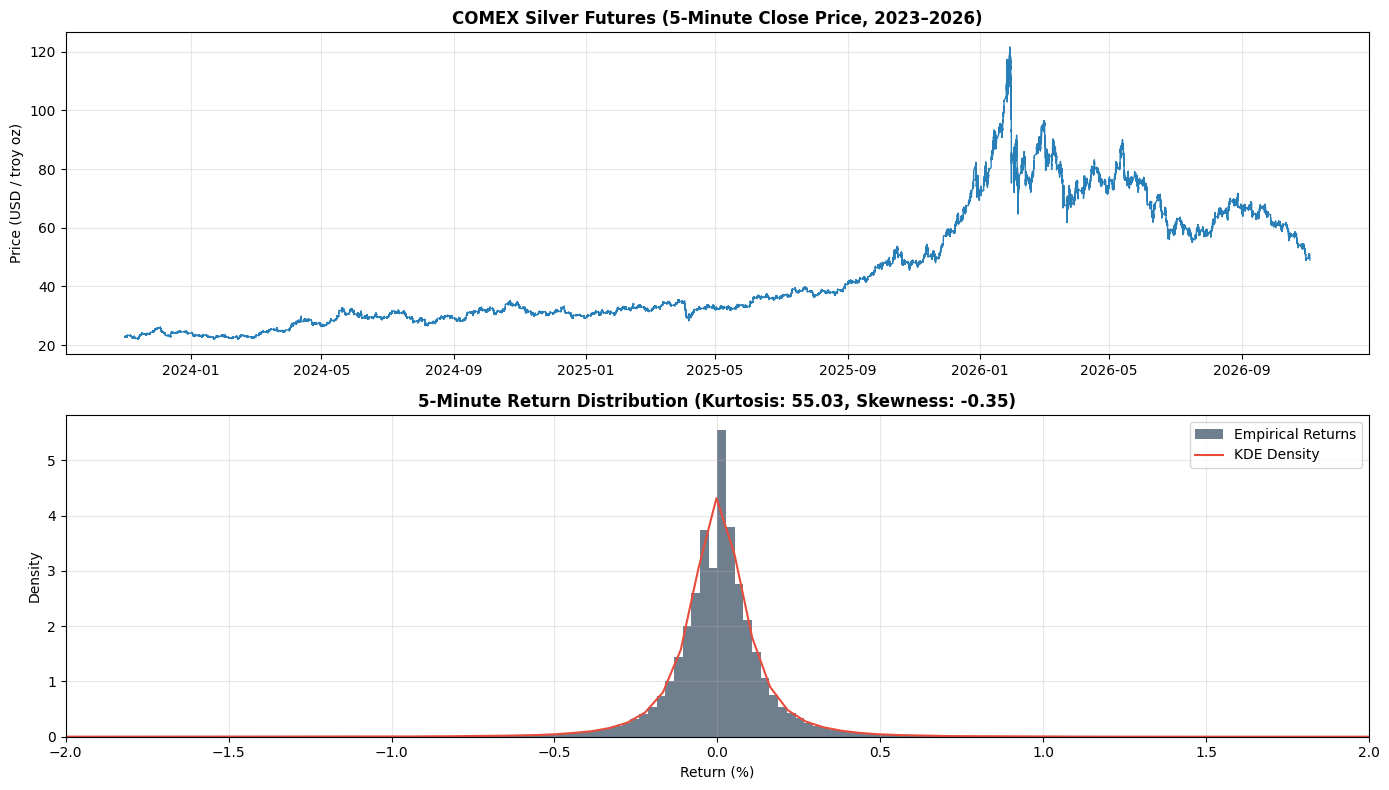

,Metric,Value
0,Mean Return (%),0.0006%
1,Median Return (%),0.0000%
2,Std Dev (%),0.1741%
3,Skewness,-0.35
4,Kurtosis,55.03 (Extreme Leptokurtosis)
5,Min Return (%),-4.56%
6,Max Return (%),6.25%


In [3]:
df["return"] = df["close"].pct_change() * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

ax1.plot(df["datetime_et"], df["close"], color="#2980b9", linewidth=1.0)
ax1.set_title("COMEX Silver Futures (5-Minute Close Price, 2023–2026)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Price (USD / troy oz)")

ret_clean = df["return"].dropna()
ax2.hist(ret_clean, bins=150, range=(-2.0, 2.0), color="#34495e", alpha=0.7, density=True, label="Empirical Returns")
sns.kdeplot(ret_clean, ax=ax2, color="#e74c3c", linewidth=1.5, label="KDE Density")
ax2.set_title(f"5-Minute Return Distribution (Kurtosis: {ret_clean.kurtosis():.2f}, Skewness: {ret_clean.skew():.2f})", fontsize=12, fontweight="bold")
ax2.set_xlabel("Return (%)")
ax2.set_ylabel("Density")
ax2.set_xlim(-2.0, 2.0)
ax2.legend(loc="upper right")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_price_and_returns.png", dpi=150)
plt.show()

ret_stats = pd.DataFrame([
    ("Mean Return (%)", f"{ret_clean.mean():.4f}%"),
    ("Median Return (%)", f"{ret_clean.median():.4f}%"),
    ("Std Dev (%)", f"{ret_clean.std():.4f}%"),
    ("Skewness", f"{ret_clean.skew():.2f}"),
    ("Kurtosis", f"{ret_clean.kurtosis():.2f} (Extreme Leptokurtosis)"),
    ("Min Return (%)", f"{ret_clean.min():.2f}%"),
    ("Max Return (%)", f"{ret_clean.max():.2f}%")
], columns=["Metric", "Value"])
display(ret_stats)

## Volatility Analysis
- Calculate rolling return volatility over a 288-bar window (equivalent to 24 trading hours) to detect volatility clustering and regime shifts.

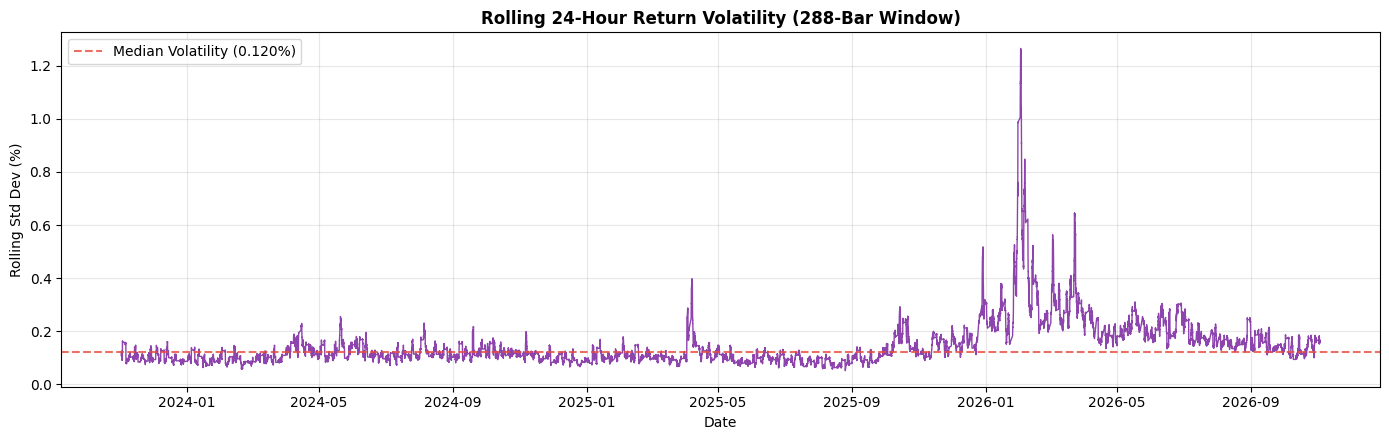

,Metric,Value
0,Median 24h Volatility,0.1200%
1,75th Percentile Volatility,0.1651%
2,95th Percentile Volatility,0.2860%
3,Maximum 24h Volatility,1.2651%


In [4]:
VOL_WINDOW = 288
df["volatility_24h"] = df["return"].rolling(window=VOL_WINDOW).std()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df["datetime_et"], df["volatility_24h"], color="#8e44ad", linewidth=1.0)
ax.axhline(df["volatility_24h"].median(), color="#e74c3c", linestyle="--", alpha=0.8, label=f"Median Volatility ({df['volatility_24h'].median():.3f}%)")
ax.set_title("Rolling 24-Hour Return Volatility (288-Bar Window)", fontsize=12, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling Std Dev (%)")
ax.legend(loc="upper left")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_rolling_volatility.png", dpi=150)
plt.show()

vol_summary = pd.DataFrame([
    ("Median 24h Volatility", f"{df['volatility_24h'].median():.4f}%"),
    ("75th Percentile Volatility", f"{df['volatility_24h'].quantile(0.75):.4f}%"),
    ("95th Percentile Volatility", f"{df['volatility_24h'].quantile(0.95):.4f}%"),
    ("Maximum 24h Volatility", f"{df['volatility_24h'].max():.4f}%")
], columns=["Metric", "Value"])
display(vol_summary)

## Volume Analysis
- Visualize 5-minute execution volume over time and examine its relationship with absolute price movement.
- Volume correlates with absolute return magnitude (volatility expansion) rather than directional bias.

Correlation (Volume vs Absolute Return):    0.4556 (strong volatility link)
Correlation (Volume vs Directional Return): -0.0545 (no directional bias)


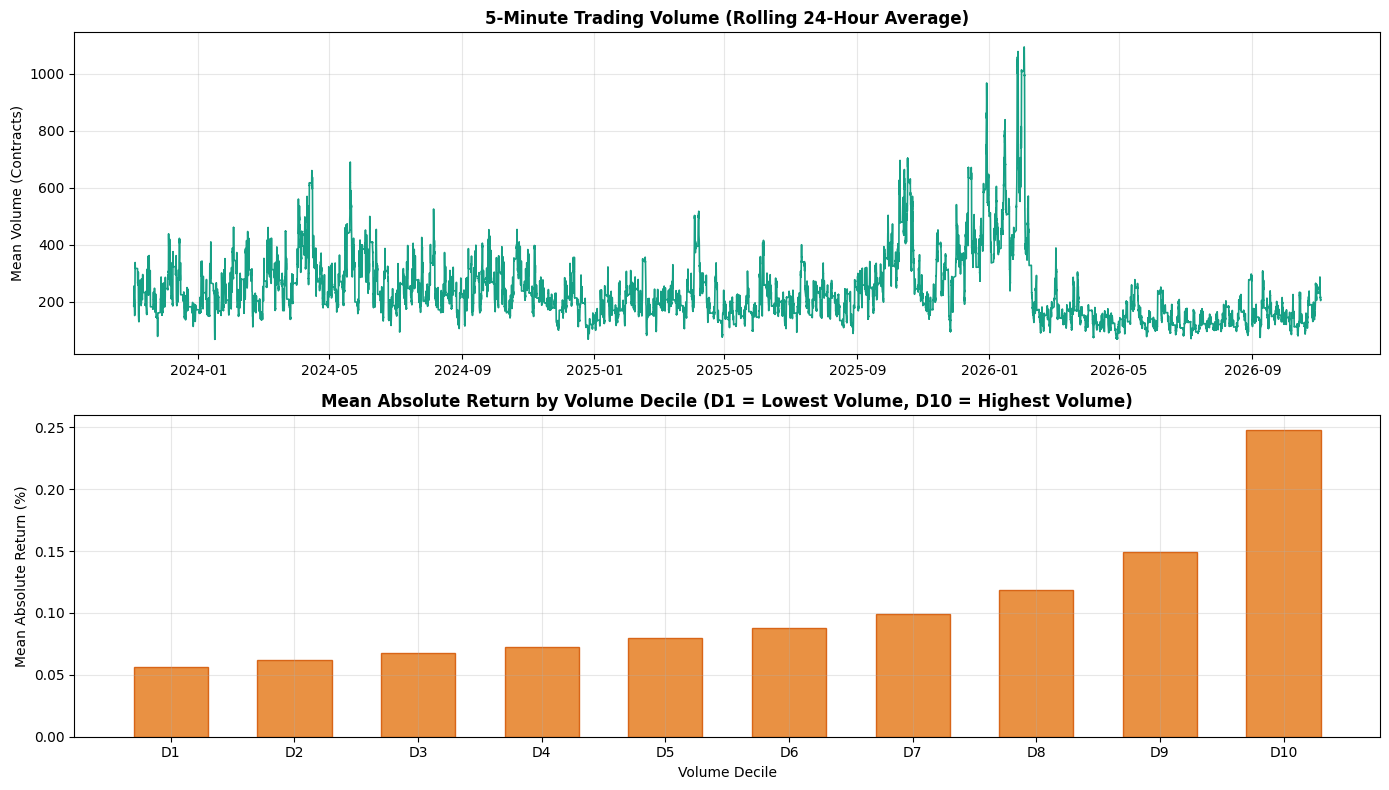

In [5]:
df["abs_return"] = df["return"].abs()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

df["volume_roll_24h"] = df["volume"].rolling(window=288).mean()
ax1.plot(df["datetime_et"], df["volume_roll_24h"], color="#16a085", linewidth=1.2)
ax1.set_title("5-Minute Trading Volume (Rolling 24-Hour Average)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Mean Volume (Contracts)")

df["vol_decile"] = pd.qcut(df["volume"], q=10, duplicates="drop")
vol_ret_profile = df.groupby("vol_decile", observed=True)["abs_return"].mean()
x_labels = [f"D{i+1}" for i in range(len(vol_ret_profile))]

ax2.bar(x_labels, vol_ret_profile.values, color="#e67e22", edgecolor="#d35400", alpha=0.85, width=0.6)
ax2.set_title("Mean Absolute Return by Volume Decile (D1 = Lowest Volume, D10 = Highest Volume)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Volume Decile")
ax2.set_ylabel("Mean Absolute Return (%)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_volume_analysis.png", dpi=150)
plt.show()

corr_vol_abs = df["volume"].corr(df["abs_return"])
corr_vol_dir = df["volume"].corr(df["return"])
print(f"Correlation (Volume vs Absolute Return):    {corr_vol_abs:.4f} (strong volatility link)")
print(f"Correlation (Volume vs Directional Return): {corr_vol_dir:.4f} (no directional bias)")

## Intraday Analysis
- Analyze average trading volume and absolute price returns by hour of the day in Eastern Time (ET).
- Identify session liquidity regimes across the 24-hour CME Globex trading cycle.

Peak Liquidity Hour:   09:00 ET (646.7 contracts/bar)
Lowest Liquidity Hour: 16:00 ET (91.6 contracts/bar)


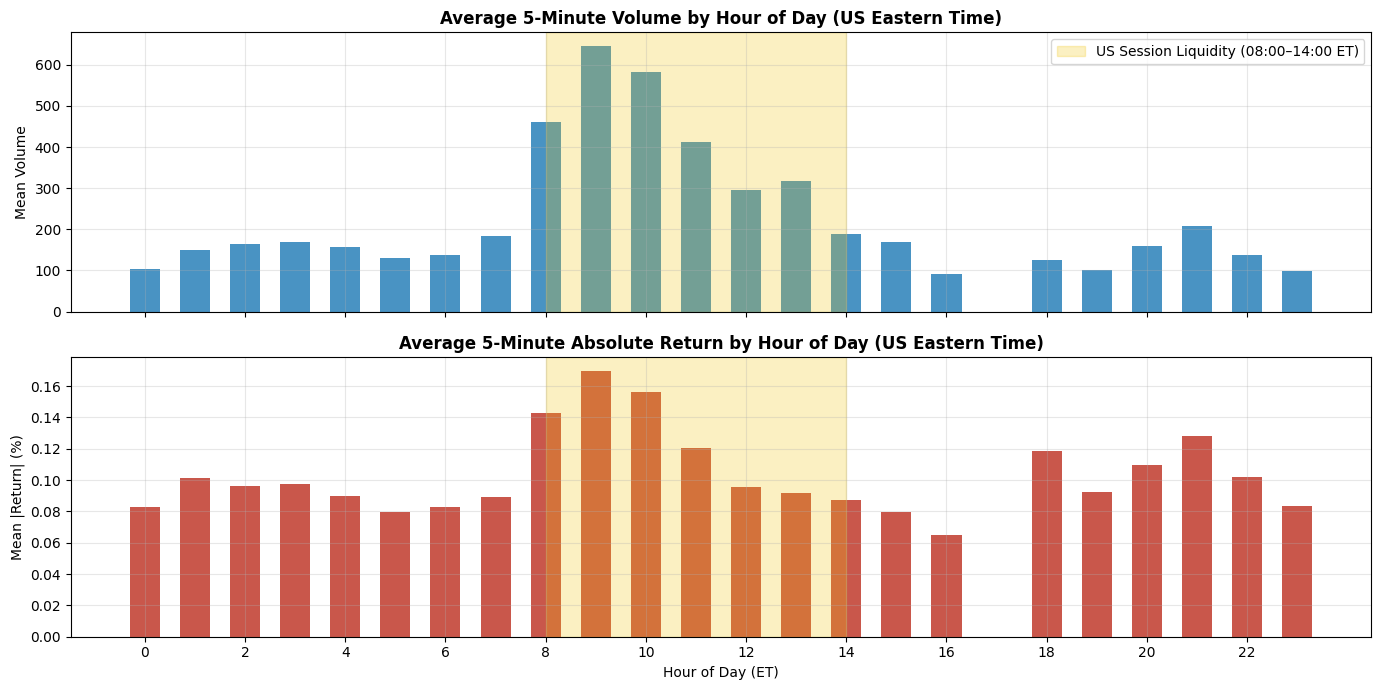

In [6]:
df["hour_et"] = df["datetime_et"].dt.hour
hourly_stats = df.groupby("hour_et").agg(
    mean_volume=("volume", "mean"),
    mean_abs_return=("abs_return", "mean")
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.bar(hourly_stats.index, hourly_stats["mean_volume"], color="#2980b9", width=0.6, alpha=0.85)
ax1.set_title("Average 5-Minute Volume by Hour of Day (US Eastern Time)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Mean Volume")
ax1.axvspan(8, 14, color="#f1c40f", alpha=0.25, label="US Session Liquidity (08:00–14:00 ET)")
ax1.legend(loc="upper right")

ax2.bar(hourly_stats.index, hourly_stats["mean_abs_return"], color="#c0392b", width=0.6, alpha=0.85)
ax2.set_title("Average 5-Minute Absolute Return by Hour of Day (US Eastern Time)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Hour of Day (ET)")
ax2.set_ylabel("Mean |Return| (%)")
ax2.set_xticks(range(0, 24, 2))
ax2.axvspan(8, 14, color="#f1c40f", alpha=0.25)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_intraday_patterns.png", dpi=150)
plt.show()

peak_vol_hour = hourly_stats["mean_volume"].idxmax()
low_vol_hour = hourly_stats["mean_volume"].idxmin()
print(f"Peak Liquidity Hour:   {peak_vol_hour:02d}:00 ET ({hourly_stats.loc[peak_vol_hour, 'mean_volume']:.1f} contracts/bar)")
print(f"Lowest Liquidity Hour: {low_vol_hour:02d}:00 ET ({hourly_stats.loc[low_vol_hour, 'mean_volume']:.1f} contracts/bar)")

## Candle Analysis
- Calculate candle body, range, and body-to-range ratio, handling zero-range candles safely.
- Evaluate candle efficiency and wick-to-body proportions.

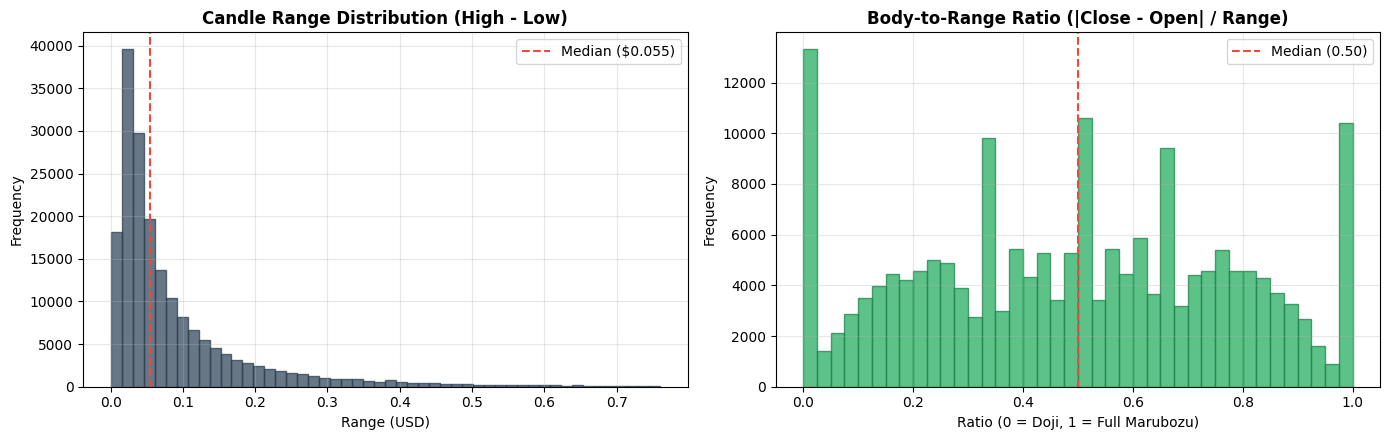

,Metric,Value
0,Median Candle Range,$0.0550
1,Median Candle Body,$0.0250
2,Median Body-to-Range Ratio,0.50
3,Zero-Range Candles (High == Low),22 (0.0116%)


In [7]:
df["candle_body"] = (df["close"] - df["open"]).abs()
df["candle_range"] = df["high"] - df["low"]
df["body_to_range"] = np.where(df["candle_range"] > 0, df["candle_body"] / df["candle_range"], 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

range_p99 = df["candle_range"].quantile(0.99)
ax1.hist(df[df["candle_range"] <= range_p99]["candle_range"], bins=50, color="#34495e", alpha=0.75, edgecolor="#2c3e50")
ax1.axvline(df["candle_range"].median(), color="#e74c3c", linestyle="--", label=f"Median (${df['candle_range'].median():.3f})")
ax1.set_title("Candle Range Distribution (High - Low)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Range (USD)")
ax1.set_ylabel("Frequency")
ax1.legend(loc="upper right")

ax2.hist(df["body_to_range"], bins=40, color="#27ae60", alpha=0.75, edgecolor="#1e824c")
ax2.axvline(df["body_to_range"].median(), color="#e74c3c", linestyle="--", label=f"Median ({df['body_to_range'].median():.2f})")
ax2.set_title("Body-to-Range Ratio (|Close - Open| / Range)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Ratio (0 = Doji, 1 = Full Marubozu)")
ax2.set_ylabel("Frequency")
ax2.legend(loc="upper right")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_candle_metrics.png", dpi=150)
plt.show()

candle_summary = pd.DataFrame([
    ("Median Candle Range", f"${df['candle_range'].median():.4f}"),
    ("Median Candle Body", f"${df['candle_body'].median():.4f}"),
    ("Median Body-to-Range Ratio", f"{df['body_to_range'].median():.2f}"),
    ("Zero-Range Candles (High == Low)", f"{(df['candle_range'] == 0).sum()} ({(df['candle_range'] == 0).mean():.4%})")
], columns=["Metric", "Value"])
display(candle_summary)

## Correlation Analysis
- Compute correlations among OHLCV levels and derived metrics (return, volume, candle body, candle range).
- Co-linearity exists among price levels, while returns correlate with volatility and range rather than direction.

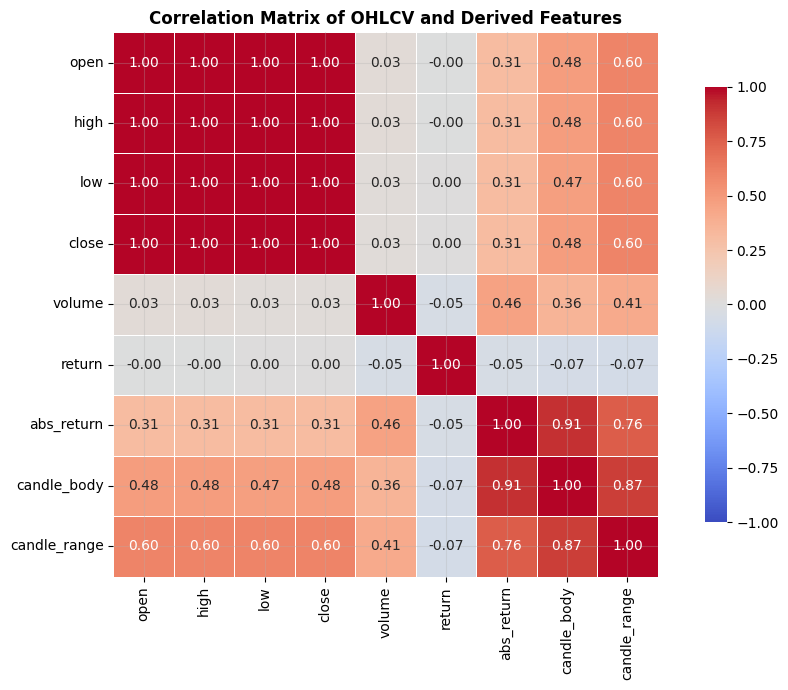

In [8]:
corr_cols = ["open", "high", "low", "close", "volume", "return", "abs_return", "candle_body", "candle_range"]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Correlation Matrix of OHLCV and Derived Features", fontsize=12, fontweight="bold")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_correlation_heatmap.png", dpi=150)
plt.show()

## Daily Market Context
- Analyze the daily roll-adjusted silver futures dataset (`SI_daily_roll-adjusted.csv`) separately to contextualize long-term macro trends.
- Note: Daily roll-adjusted prices account for contract roll-yield and are not merged with front-month intraday levels.

Daily Historical Span: 7,775 trading sessions (1995-11-29 to 2026-11-02)
Daily Return Std Dev:  2.00% (Annualized: 31.75%)


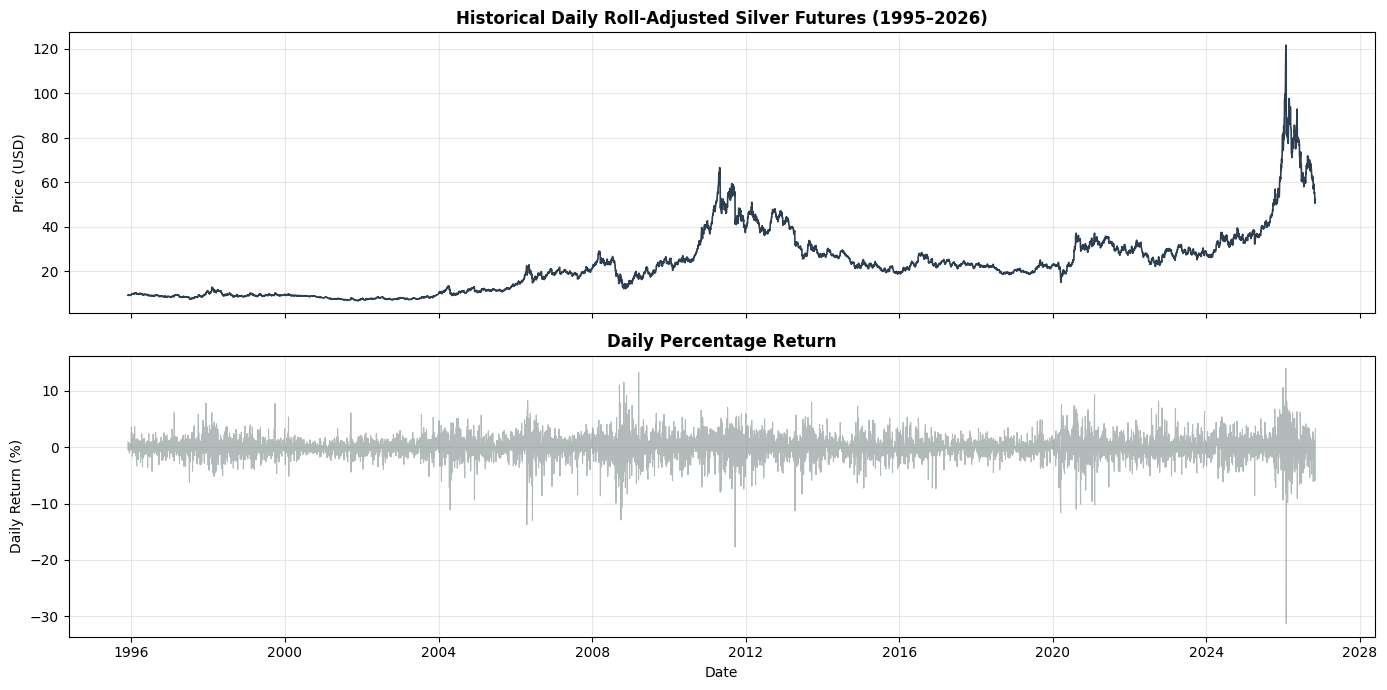

In [9]:
def load_daily_data(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing daily dataset: {path}")
    df_daily = pd.read_csv(path)
    df_daily["date"] = pd.to_datetime(df_daily["date"])
    df_daily = df_daily.sort_values("date").reset_index(drop=True)
    df_daily["daily_return"] = df_daily["close"].pct_change() * 100
    return df_daily

daily_df = load_daily_data(DAILY_FILE)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(daily_df["date"], daily_df["close"], color="#2c3e50", linewidth=1.2)
ax1.set_title(f"Historical Daily Roll-Adjusted Silver Futures ({daily_df['date'].dt.year.min()}–{daily_df['date'].dt.year.max()})", fontsize=12, fontweight="bold")
ax1.set_ylabel("Price (USD)")

ax2.plot(daily_df["date"], daily_df["daily_return"], color="#7f8c8d", alpha=0.6, linewidth=0.8)
ax2.set_title("Daily Percentage Return", fontsize=12, fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Daily Return (%)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "07_daily_context.png", dpi=150)
plt.show()

print(f"Daily Historical Span: {len(daily_df):,} trading sessions ({daily_df['date'].min().date()} to {daily_df['date'].max().date()})")
print(f"Daily Return Std Dev:  {daily_df['daily_return'].std():.2f}% (Annualized: {daily_df['daily_return'].std() * np.sqrt(252):.2f}%)")

## EDA Summary
- Summary of core empirical findings and their direct implications for feature engineering.

In [10]:
eda_findings = pd.DataFrame([
    ("Dataset Dimension", f"{len(df):,} 5-minute candles across 1,098 calendar days"),
    ("Price Dynamic", f"Traded between ${df['close'].min():.2f} and ${df['close'].max():.2f} (mean ${df['close'].mean():.2f})"),
    ("Return Distribution", f"Leptokurtic (Kurtosis: {ret_clean.kurtosis():.2f}) with heavy tails; requires robust scaling"),
    ("Volatility Clustering", f"Strong temporal persistence; motivates rolling standard deviation and ATR features"),
    ("Intraday Cyclicality", f"Peak liquidity between 08:00–14:00 ET; motivates cyclical time-of-day feature encodings"),
    ("Volume-Volatility Coupling", f"Volume correlates with absolute return ({corr_vol_abs:.2f}) but not directional return ({corr_vol_dir:.2f})"),
    ("Candle Structure", f"Median range is ${df['candle_range'].median():.4f}; 22 zero-range candles safely handled"),
    ("Macro Context", f"Daily series reflects long-term structural regimes across {len(daily_df):,} sessions (1995–2026)")
], columns=["Dimension", "Observation & Modeling Implication"])

display(eda_findings)

,Dimension,Observation & Modeling Implication
0,Dataset Dimension,"189,798 5-minute candles across 1,098 calendar..."
1,Price Dynamic,Traded between $21.96 and $121.66 (mean $44.37)
2,Return Distribution,Leptokurtic (Kurtosis: 55.03) with heavy tails...
3,Volatility Clustering,Strong temporal persistence; motivates rolling...
4,Intraday Cyclicality,Peak liquidity between 08:00–14:00 ET; motivat...
5,Volume-Volatility Coupling,Volume correlates with absolute return (0.46) ...
6,Candle Structure,Median range is $0.0550; 22 zero-range candles...
7,Macro Context,Daily series reflects long-term structural reg...
